
# 00D — UNSW-NB15 Mixed-Label Fingerprint Benign-Shift Diagnostic

**Experiment 1 v2 — diagnostic only; no formal model selection**

This notebook tests the highest-yield hypothesis remaining after 00C:

> Are the benign observations in `development` that fail the calibration threshold predominantly members of **mixed-label/conflicting feature-fingerprint groups**?

It reuses the already-persisted benign-only reconstruction errors generated by 00C. It does **not** retrain a model, does **not** change PRE-01 or PRE-02, does **not** access final-test features/outcomes, and does **not** compute attack scores or attack performance.

The three populations compared are:

1. `benign_threshold_calibration` — expected to contain only pure-benign fingerprints.
2. `development` benign observations belonging to **pure-benign fingerprint groups**.
3. `development` benign observations belonging to **mixed-label/conflicting fingerprint groups**.

The existing frozen 99th-percentile calibration rule is recomputed from the persisted calibration-benign `total_mse` scores.

**This notebook cannot authorize formal Notebook 01.** Its output is diagnostic evidence for deciding whether the remaining failure is primarily due to mixed-label fingerprint composition or whether a deeper within-source/capture-regime imbalance remains.


In [1]:

# ============================================================
# 00D-0. IMPORTS, HASH/IO HELPERS, AND CONFIGURATION
# ============================================================
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import numpy as np
import pandas as pd

DATASET_NAME = "UNSW-NB15"
PROTOCOL_VERSION = "Experiment_1_v2"
MODEL_BRANCH_VERSION = "v2_source_stratified_20260918"
PRE02_BRANCH_SUBDIR = "preprocessing_representation_s12_s14_v3_source_stratified_20260918"

PROJECT_FOLDER_NAME = "EXPERIMENT1_V2"
PRIMARY_PROJECT = Path("/content/drive/MyDrive") / PROJECT_FOLDER_NAME
FALLBACK_PROJECT = Path("/content/exp1v2_google_drive/MyDrive") / PROJECT_FOLDER_NAME
PROJECT_ROOT_OVERRIDE = None

PRE01_DIRNAME = "partitioning_s8_s11_v2_source_stratified_seed20260914"
SOURCE_00C_STAGE = "preformal_pre02_error_decomposition_diagnostic"
OUTPUT_STAGE = "preformal_mixed_label_fingerprint_diagnostic"

EXPECTED_MIXED_CLASS = "mixed-label/conflicting group"
EXPECTED_PURE_BENIGN_CLASS = "pure benign group"

def require(condition, message):
    if not bool(condition):
        print("\nEXPERIMENT 1 v2 DIAGNOSTIC INTEGRITY: FAIL")
        print("Formal Notebook 01 remains BLOCKED.")
        raise RuntimeError(str(message))

def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

def canonical_json_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()

def atomic_write_csv(path, df):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)

def atomic_write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)
    os.replace(tmp, path)

print("Dataset:", DATASET_NAME)
print("Protocol:", PROTOCOL_VERSION)
print("Branch:", MODEL_BRANCH_VERSION)
print("This is a benign-only diagnostic. Formal Notebook 01 remains blocked.")


Dataset: UNSW-NB15
Protocol: Experiment_1_v2
Branch: v2_source_stratified_20260918
This is a benign-only diagnostic. Formal Notebook 01 remains blocked.


In [2]:

# ============================================================
# 00D-1. VERIFIED GOOGLE DRIVE MOUNT AND PATH BINDING
# ============================================================
def resolve_project_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        p = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        require(p.exists(), f"PROJECT_ROOT_OVERRIDE does not exist: {p}")
        return p

    if PRIMARY_PROJECT.exists():
        return PRIMARY_PROJECT.resolve()

    # Mount Google Drive only if needed.
    try:
        from google.colab import drive
        Path("/content/drive").mkdir(parents=True, exist_ok=True)
        drive.mount("/content/drive", force_remount=False)
    except Exception as exc:
        print("Primary Drive mount attempt:", repr(exc))

    if PRIMARY_PROJECT.exists():
        return PRIMARY_PROJECT.resolve()

    # Accept the alternate mount used by earlier Experiment 1 v2 recovery notebooks.
    if FALLBACK_PROJECT.exists():
        return FALLBACK_PROJECT.resolve()

    try:
        from google.colab import drive
        Path("/content/exp1v2_google_drive").mkdir(parents=True, exist_ok=True)
        drive.mount("/content/exp1v2_google_drive", force_remount=False)
    except Exception as exc:
        print("Fallback Drive mount attempt:", repr(exc))

    require(FALLBACK_PROJECT.exists(),
            "Could not locate EXPERIMENT1_V2 on mounted Google Drive.")
    return FALLBACK_PROJECT.resolve()

PROJECT_ROOT = resolve_project_root()
DATASET_ROOT = PROJECT_ROOT / "DATASETS" / DATASET_NAME
MODELLING_ROOT = DATASET_ROOT / "modelling"

PRE01_ROOT = DATASET_ROOT / PRE01_DIRNAME
PARTITION_MEMBERSHIP_PATH = PRE01_ROOT / "partition_membership.parquet"

SOURCE_00C_ROOT = MODELLING_ROOT / SOURCE_00C_STAGE / MODEL_BRANCH_VERSION
SOURCE_00C_MANIFEST_PATH = SOURCE_00C_ROOT / "diagnostic_manifest.json"
CAL_ERRORS_PATH = SOURCE_00C_ROOT / "calibration_benign_block_errors.parquet"
DEV_ERRORS_PATH = SOURCE_00C_ROOT / "development_benign_block_errors.parquet"

THRESHOLD_CONTRACT_PATH = PROJECT_ROOT / "global" / "threshold_contract.json"

OUTPUT_ROOT = MODELLING_ROOT / OUTPUT_STAGE / MODEL_BRANCH_VERSION
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

for p, label in [
    (PARTITION_MEMBERSHIP_PATH, "corrected PRE-01 partition membership"),
    (SOURCE_00C_MANIFEST_PATH, "00C diagnostic manifest"),
    (CAL_ERRORS_PATH, "00C calibration-benign row errors"),
    (DEV_ERRORS_PATH, "00C development-benign row errors"),
    (THRESHOLD_CONTRACT_PATH, "global threshold contract"),
]:
    require(Path(p).exists(), f"Missing {label}: {p}")

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PRE-01 root:", PRE01_ROOT)
print("00C root:", SOURCE_00C_ROOT)
print("00D output root:", OUTPUT_ROOT)


Mounted at /content/drive
PROJECT_ROOT: /content/drive/MyDrive/EXPERIMENT1_V2
PRE-01 root: /content/drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/partitioning_s8_s11_v2_source_stratified_seed20260914
00C root: /content/drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_pre02_error_decomposition_diagnostic/v2_source_stratified_20260918
00D output root: /content/drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_mixed_label_fingerprint_diagnostic/v2_source_stratified_20260918


In [3]:

# ============================================================
# 00D-2. PROVENANCE AND CONTRACT GATES
# ============================================================
with open(SOURCE_00C_MANIFEST_PATH, "r", encoding="utf-8") as f:
    M00C = json.load(f)
with open(THRESHOLD_CONTRACT_PATH, "r", encoding="utf-8") as f:
    THRESHOLD_CONTRACT = json.load(f)

require(M00C.get("dataset") == DATASET_NAME, "00C manifest dataset mismatch.")
require(M00C.get("protocol_version") == PROTOCOL_VERSION, "00C protocol mismatch.")
require(M00C.get("model_branch_version") == MODEL_BRANCH_VERSION, "00C branch mismatch.")
require(M00C.get("formal_notebook01_authorized") is False,
        "Unexpected 00C state: formal Notebook 01 must still be blocked.")
require(M00C.get("attack_scores_computed") is False,
        "00C indicates attack scores were computed; stop and investigate.")
require(M00C.get("final_test_outcomes_accessed") is False,
        "00C indicates final-test outcomes were accessed; stop and investigate.")

expected_partition_file_hash = (
    M00C.get("upstream_identity", {}).get("partition_manifest_file_sha256")
)
require(bool(expected_partition_file_hash),
        "00C manifest lacks partition_manifest_file_sha256.")
actual_partition_file_hash = sha256_file(PARTITION_MEMBERSHIP_PATH)
require(actual_partition_file_hash.lower() == str(expected_partition_file_hash).lower(),
        "Corrected PRE-01 partition file hash does not match 00C upstream identity.")

require(float(THRESHOLD_CONTRACT.get("primary_percentile")) == 99.0,
        "Threshold contract primary percentile is not 99.")
require(THRESHOLD_CONTRACT.get("decision_operator") == ">",
        "Threshold decision operator is not '>'.")
require(THRESHOLD_CONTRACT.get("quantile_implementation") == "numpy.quantile",
        "Unexpected quantile implementation.")
require(THRESHOLD_CONTRACT.get("quantile_method") == "linear",
        "Unexpected quantile method.")

print("PASS: corrected PRE-01 membership is the same partition used by 00C.")
print("PASS: frozen 99th-percentile threshold contract verified.")
print("Formal Notebook 01 remains BLOCKED.")


PASS: corrected PRE-01 membership is the same partition used by 00C.
PASS: frozen 99th-percentile threshold contract verified.
Formal Notebook 01 remains BLOCKED.


In [4]:

# ============================================================
# 00D-2B. BIND READ-ONLY TO CORRECTED PRE-02 TRANSFORMED DATA
#          FOR THE SEVEN CT_* STANDARDIZED-VALUE DIAGNOSTIC
# ============================================================
import pyarrow.parquet as pq

PRE02_ROOT = DATASET_ROOT / PRE02_BRANCH_SUBDIR
PRE02_REPORT = PRE02_ROOT / "reports" / "preprocessing_integrity_report.json"
REPRESENTATION_PATH = PRE02_ROOT / "manifests" / "transformed_representation_manifest.json"
CORRUPTION_PATH = PRE02_ROOT / "manifests" / "corruption_group_manifest.json"

for p, label in [
    (PRE02_REPORT, "corrected PRE-02 integrity report"),
    (REPRESENTATION_PATH, "transformed representation manifest"),
    (CORRUPTION_PATH, "corruption group manifest"),
]:
    require(p.exists(), f"Missing {label}: {p}")

with open(PRE02_REPORT, "r", encoding="utf-8") as f:
    PRE02_INTEGRITY = json.load(f)
with open(REPRESENTATION_PATH, "r", encoding="utf-8") as f:
    REPRESENTATION = json.load(f)
with open(CORRUPTION_PATH, "r", encoding="utf-8") as f:
    CORRUPTION = json.load(f)

require(
    PRE02_INTEGRITY.get("final_status") in {"PASS", "PASS_WITH_NONBLOCKING_WARNINGS"},
    f"Corrected PRE-02 is not in an acceptable state: {PRE02_INTEGRITY.get('final_status')}"
)

FEATURE_NAMES = list(REPRESENTATION.get("exact_transformed_feature_order", []))
INPUT_DIM = int(REPRESENTATION.get("total_transformed_dimensionality", -1))
TRANSFORMED_DTYPE = str(REPRESENTATION.get("transformed_dtype"))
NUM_NAMES = list(REPRESENTATION.get("transformed_numerical_feature_names", []))
NUM_IDX = np.asarray(list(map(int, CORRUPTION.get("numerical_indices", []))), dtype=np.int64)

require(INPUT_DIM > 0 and len(FEATURE_NAMES) == INPUT_DIM,
        "Invalid corrected PRE-02 transformed representation.")
require(len(NUM_NAMES) == len(NUM_IDX) and len(NUM_NAMES) > 0,
        "Numerical names/indices mismatch in corrected PRE-02 manifests.")
require(TRANSFORMED_DTYPE in {"float32", "float64"},
        f"Unsupported transformed dtype: {TRANSFORMED_DTYPE}")

# Resolve the exact seven CT-density features against the frozen schema.
# The UNSW master deliberately preserves the literal 'ct_src_ ltm' spelling.
CT7_REQUESTED = [
    "ct_dst_sport_ltm",
    "ct_src_dport_ltm",
    "ct_dst_src_ltm",
    "ct_dst_ltm",
    "ct_src_ ltm",
    "ct_srv_dst",
    "ct_srv_src",
]
# Accept the no-space alias only as a lookup fallback; report the actual frozen name.
_aliases = {
    "ct_src_ltm": "ct_src_ ltm",
}
_num_name_set = set(map(str, NUM_NAMES))
CT7_ACTUAL = []
for requested in CT7_REQUESTED:
    actual = requested
    if actual not in _num_name_set:
        actual = _aliases.get(requested, requested)
    require(actual in _num_name_set,
            f"Required CT-density feature is absent from frozen PRE-02 numerical schema: {requested!r}")
    CT7_ACTUAL.append(actual)

require(len(set(CT7_ACTUAL)) == 7, f"CT feature resolution is not one-to-one: {CT7_ACTUAL}")

num_name_to_transformed_idx = {
    str(name): int(idx) for name, idx in zip(NUM_NAMES, NUM_IDX.tolist())
}
CT7_TRANSFORMED_IDX = np.asarray(
    [num_name_to_transformed_idx[name] for name in CT7_ACTUAL],
    dtype=np.int64,
)

LOCAL_CACHE_ROOT = Path("/content/experiment1_v2_00d_cache") / REPRESENTATION.get(
    "feature_order_hash", "unknown"
)
LOCAL_CACHE_ROOT.mkdir(parents=True, exist_ok=True)

def _pre02_paths(partition):
    require(partition in {"benign_threshold_calibration", "development"},
            f"00D does not authorize access to partition={partition!r}")
    return (
        PRE02_ROOT / "transformed_partitions" / f"{partition}_transformed.parquet",
        PRE02_ROOT / "transformed_partitions" / f"{partition}_transformed_alignment.parquet",
        PRE02_ROOT / "raw_partitions" / f"{partition}_raw_metadata.parquet",
    )

def _part_info(partition):
    info = REPRESENTATION.get("per_partition", {}).get(partition)
    require(isinstance(info, dict), f"Representation manifest lacks {partition}.")
    return info

def _load_metadata(partition):
    _, alignment_path, metadata_path = _pre02_paths(partition)
    require(alignment_path.exists() and metadata_path.exists(),
            f"Missing PRE-02 alignment/metadata for {partition}.")
    alignment = pd.read_parquet(alignment_path)
    metadata = pd.read_parquet(metadata_path)
    require(len(alignment) == len(metadata),
            f"Alignment/metadata row-count mismatch for {partition}.")
    require(
        alignment["row_id"].astype(str).reset_index(drop=True).equals(
            metadata["row_id"].astype(str).reset_index(drop=True)
        ),
        f"Alignment/metadata row_id mismatch for {partition}."
    )
    require("binary_label" in metadata.columns, f"binary_label missing from {partition} metadata.")
    metadata = metadata.copy()
    metadata["binary_label"] = pd.to_numeric(
        metadata["binary_label"], errors="raise"
    ).astype(int)
    return metadata.reset_index(drop=True)

def _ensure_local_matrix(partition):
    model_path, _, _ = _pre02_paths(partition)
    info = _part_info(partition)
    require(model_path.exists(), f"Missing transformed parquet for {partition}: {model_path}")
    require(sha256_file(model_path) == info.get("transformed_artifact_sha256"),
            f"Transformed parquet SHA mismatch for {partition}.")
    rows = int(info["transformed_row_count"])
    cache_path = LOCAL_CACHE_ROOT / f"{partition}.npy"
    cache_meta_path = LOCAL_CACHE_ROOT / f"{partition}.cache.json"
    expected_meta = {
        "source_sha256": info["transformed_artifact_sha256"],
        "rows": rows,
        "columns": INPUT_DIM,
        "dtype": TRANSFORMED_DTYPE,
        "feature_order_hash": REPRESENTATION.get("feature_order_hash"),
    }
    if cache_path.exists() and cache_meta_path.exists():
        try:
            with open(cache_meta_path, "r", encoding="utf-8") as f:
                observed = json.load(f)
            mm = np.load(cache_path, mmap_mode="r")
            if (
                observed == expected_meta
                and mm.shape == (rows, INPUT_DIM)
                and str(mm.dtype) == TRANSFORMED_DTYPE
            ):
                return mm
        except Exception:
            pass
        cache_path.unlink(missing_ok=True)
        cache_meta_path.unlink(missing_ok=True)

    dtype = np.dtype(TRANSFORMED_DTYPE)
    mm = np.lib.format.open_memmap(
        cache_path, mode="w+", dtype=dtype, shape=(rows, INPUT_DIM)
    )
    pf = pq.ParquetFile(model_path)
    require(pf.schema_arrow.names == FEATURE_NAMES,
            f"Feature order mismatch for {partition}.")
    offset = 0
    for batch in pf.iter_batches(batch_size=50_000, columns=FEATURE_NAMES):
        arr = batch.to_pandas().to_numpy(dtype=dtype, copy=False)
        require(np.isfinite(arr).all(), f"Non-finite transformed value in {partition}.")
        mm[offset:offset+len(arr)] = arr
        offset += len(arr)
    require(offset == rows, f"Cached row count mismatch for {partition}.")
    mm.flush()
    del mm
    atomic_write_json(cache_meta_path, expected_meta)
    return np.load(cache_path, mmap_mode="r")

CAL_META = _load_metadata("benign_threshold_calibration")
DEV_META = _load_metadata("development")
require((CAL_META["binary_label"] == 0).all(),
        "Calibration partition is not benign-only.")
DEV_BENIGN_MATRIX_IDX = np.flatnonzero(
    DEV_META["binary_label"].to_numpy(dtype=int) == 0
)
require(len(DEV_BENIGN_MATRIX_IDX) > 0, "No development benign rows found.")

CAL_MM = _ensure_local_matrix("benign_threshold_calibration")
DEV_MM = _ensure_local_matrix("development")

print("Resolved CT-density features:", CT7_ACTUAL)
print("Resolved transformed indices:", CT7_TRANSFORMED_IDX.tolist())
print("Calibration benign rows:", f"{len(CAL_META):,}")
print("Development benign rows:", f"{len(DEV_BENIGN_MATRIX_IDX):,}")
print("Final-test access: NONE")


Resolved CT-density features: ['ct_dst_sport_ltm', 'ct_src_dport_ltm', 'ct_dst_src_ltm', 'ct_dst_ltm', 'ct_src_ ltm', 'ct_srv_dst', 'ct_srv_src']
Resolved transformed indices: [36, 35, 37, 33, 34, 32, 31]
Calibration benign rows: 332,815
Development benign rows: 221,876
Final-test access: NONE


In [5]:

# ============================================================
# 00D-3. LOAD ONLY BENIGN SCORE ROWS + NON-OUTCOME GROUP METADATA
# ============================================================
# The 00C parquets already contain only calibration benign and development benign
# observations. We therefore do not load attack labels here.

cal = pd.read_parquet(
    CAL_ERRORS_PATH,
    columns=["row_id", "total_mse"],
    engine="pyarrow",
)
dev = pd.read_parquet(
    DEV_ERRORS_PATH,
    columns=["row_id", "total_mse"],
    engine="pyarrow",
)

require(len(cal) > 0 and len(dev) > 0, "00C benign row-level score files are empty.")
require(not cal["row_id"].duplicated().any(), "Duplicate row_id in calibration error file.")
require(not dev["row_id"].duplicated().any(), "Duplicate row_id in development benign error file.")

# Load only non-outcome columns from the relevant PRE-01 roles.
membership_cols = [
    "row_id",
    "feature_fingerprint",
    "fingerprint_group_class",
    "partition",
]

cal_mem = pd.read_parquet(
    PARTITION_MEMBERSHIP_PATH,
    columns=membership_cols,
    filters=[("partition", "==", "benign_threshold_calibration")],
    engine="pyarrow",
)
dev_mem = pd.read_parquet(
    PARTITION_MEMBERSHIP_PATH,
    columns=membership_cols,
    filters=[("partition", "==", "development")],
    engine="pyarrow",
)

calx = cal.merge(cal_mem, on="row_id", how="left", validate="one_to_one")
devx = dev.merge(dev_mem, on="row_id", how="left", validate="one_to_one")

require(calx["partition"].eq("benign_threshold_calibration").all(),
        "Calibration score rows did not map exactly to calibration membership.")
require(devx["partition"].eq("development").all(),
        "Development-benign score rows did not map exactly to development membership.")
require(calx["feature_fingerprint"].notna().all() and devx["feature_fingerprint"].notna().all(),
        "Missing feature_fingerprint after membership merge.")
require(calx["fingerprint_group_class"].notna().all() and devx["fingerprint_group_class"].notna().all(),
        "Missing fingerprint_group_class after membership merge.")

observed_cal_classes = sorted(calx["fingerprint_group_class"].astype(str).unique().tolist())
observed_dev_classes = sorted(devx["fingerprint_group_class"].astype(str).unique().tolist())

require(set(observed_cal_classes) == {EXPECTED_PURE_BENIGN_CLASS},
        f"Calibration benign contains unexpected fingerprint classes: {observed_cal_classes}")
require(set(observed_dev_classes).issubset({EXPECTED_PURE_BENIGN_CLASS, EXPECTED_MIXED_CLASS}),
        f"Development benign contains unexpected fingerprint classes: {observed_dev_classes}")

print("Calibration rows:", f"{len(calx):,}")
print("Development benign rows:", f"{len(devx):,}")
print("Calibration classes:", observed_cal_classes)
print("Development benign classes:", observed_dev_classes)
print("Attack labels/scores accessed: NO")
print("Final-test features/outcomes accessed: NO")


# Bind 00C benign-score row order to PRE-02 transformed row order.
require(
    cal["row_id"].astype(str).reset_index(drop=True).equals(
        CAL_META["row_id"].astype(str).reset_index(drop=True)
    ),
    "00C calibration-benign score row order differs from PRE-02 calibration matrix order."
)
_dev_benign_meta = DEV_META.iloc[DEV_BENIGN_MATRIX_IDX].reset_index(drop=True)
require(
    dev["row_id"].astype(str).reset_index(drop=True).equals(
        _dev_benign_meta["row_id"].astype(str).reset_index(drop=True)
    ),
    "00C development-benign score row order differs from PRE-02 development-benign matrix order."
)

# Map each benign score row to its transformed matrix index.
calx["_matrix_row_idx"] = np.arange(len(calx), dtype=np.int64)
_dev_row_to_matrix_idx = pd.Series(
    DEV_BENIGN_MATRIX_IDX,
    index=_dev_benign_meta["row_id"].astype(str)
)
devx["_matrix_row_idx"] = (
    devx["row_id"].astype(str).map(_dev_row_to_matrix_idx).astype(np.int64)
)
require(devx["_matrix_row_idx"].notna().all(),
        "Could not map every development-benign score row to transformed matrix row.")


Calibration rows: 332,815
Development benign rows: 221,876
Calibration classes: ['pure benign group']
Development benign classes: ['mixed-label/conflicting group', 'pure benign group']
Attack labels/scores accessed: NO
Final-test features/outcomes accessed: NO


In [6]:

# ============================================================
# 00D-4. RECOMPUTE FROZEN CALIBRATION THRESHOLD,
#        SPLIT PURE/MIXED BENIGN, AND ADD CT-DENSITY |z|
# ============================================================
q_method = THRESHOLD_CONTRACT["quantile_method"]
threshold = float(np.quantile(
    calx["total_mse"].to_numpy(dtype=np.float64),
    0.99,
    method=q_method,
))

cal_exceed = calx["total_mse"].to_numpy(dtype=np.float64) > threshold
devx["above_calibration_p99"] = (
    devx["total_mse"].to_numpy(dtype=np.float64) > threshold
)

dev_pure = devx.loc[
    devx["fingerprint_group_class"].eq(EXPECTED_PURE_BENIGN_CLASS)
].copy()
dev_mixed = devx.loc[
    devx["fingerprint_group_class"].eq(EXPECTED_MIXED_CLASS)
].copy()

quantiles = [0.25, 0.50, 0.75, 0.90, 0.95, 0.97, 0.99, 0.995]

def ct7_abs_z_metrics(mm, matrix_indices):
    matrix_indices = np.asarray(matrix_indices, dtype=np.int64)
    require(len(matrix_indices) > 0, "CT7 diagnostic population is empty.")
    # PRE-02 numerical transformed values are StandardScaler z-space.
    arr = np.asarray(mm[matrix_indices][:, CT7_TRANSFORMED_IDX], dtype=np.float64)
    a = np.abs(arr)
    row_median = np.median(a, axis=1)
    result = {
        # Requested principal addition: pooled median |z| across the seven CT features.
        "ct7_pooled_median_abs_z": float(np.median(a)),
        # Supporting measures retained so the result is not dependent on one aggregation.
        "ct7_median_of_row_median_abs_z": float(np.median(row_median)),
        "ct7_mean_abs_z": float(np.mean(a)),
        "ct7_pct_values_gt_5_abs_z": float(np.mean(a > 5.0) * 100.0),
        "ct7_pct_values_gt_10_abs_z": float(np.mean(a > 10.0) * 100.0),
    }
    per_feature = {
        name: float(np.median(a[:, j]))
        for j, name in enumerate(CT7_ACTUAL)
    }
    return result, per_feature

cal_ct, cal_ct_feature = ct7_abs_z_metrics(
    CAL_MM, calx["_matrix_row_idx"].to_numpy(dtype=np.int64)
)
pure_ct, pure_ct_feature = ct7_abs_z_metrics(
    DEV_MM, dev_pure["_matrix_row_idx"].to_numpy(dtype=np.int64)
) if len(dev_pure) else ({}, {})
mixed_ct, mixed_ct_feature = ct7_abs_z_metrics(
    DEV_MM, dev_mixed["_matrix_row_idx"].to_numpy(dtype=np.int64)
) if len(dev_mixed) else ({}, {})

def summarize_scores(name, df, ct_metrics, development_total=None):
    x = df["total_mse"].to_numpy(dtype=np.float64)
    out = {
        "population": name,
        "rows": int(len(df)),
        "unique_fingerprints": int(df["feature_fingerprint"].nunique()),
        "share_of_development_benign": (
            float(len(df) / development_total)
            if development_total is not None and development_total > 0
            else np.nan
        ),
        "mean_total_mse": float(np.mean(x)) if len(x) else np.nan,
        "median_total_mse": float(np.median(x)) if len(x) else np.nan,
        "above_calibration_p99_rows": int(np.sum(x > threshold)) if len(x) else 0,
        "above_calibration_p99_rate": float(np.mean(x > threshold)) if len(x) else np.nan,
    }
    out.update(ct_metrics)
    for q in quantiles:
        out[f"mse_p{str(q*100).replace('.', '_')}"] = (
            float(np.quantile(x, q, method=q_method)) if len(x) else np.nan
        )
    return out

SUMMARY = pd.DataFrame([
    summarize_scores("calibration_benign_all_pure", calx, cal_ct),
    summarize_scores(
        "development_benign_pure_fingerprint",
        dev_pure,
        pure_ct,
        len(devx),
    ),
    summarize_scores(
        "development_benign_mixed_fingerprint",
        dev_mixed,
        mixed_ct,
        len(devx),
    ),
])

# Feature-by-feature CT-density table to confirm whether the same mechanism
# appears across all seven counters rather than only in the pooled statistic.
CT7_PER_FEATURE = pd.DataFrame([
    {
        "feature": feature,
        "calibration_benign_median_abs_z": cal_ct_feature.get(feature, np.nan),
        "development_benign_pure_fingerprint_median_abs_z":
            pure_ct_feature.get(feature, np.nan),
        "development_benign_mixed_fingerprint_median_abs_z":
            mixed_ct_feature.get(feature, np.nan),
    }
    for feature in CT7_ACTUAL
])
CT7_PER_FEATURE["pure_to_cal_median_abs_z_ratio"] = (
    CT7_PER_FEATURE["development_benign_pure_fingerprint_median_abs_z"] /
    CT7_PER_FEATURE["calibration_benign_median_abs_z"].replace(0, np.nan)
)
CT7_PER_FEATURE["mixed_to_cal_median_abs_z_ratio"] = (
    CT7_PER_FEATURE["development_benign_mixed_fingerprint_median_abs_z"] /
    CT7_PER_FEATURE["calibration_benign_median_abs_z"].replace(0, np.nan)
)

all_dev_fp = int(devx["above_calibration_p99"].sum())
all_dev_rows = int(len(devx))

fp_rows = []
for name, df in [
    ("pure_benign_fingerprint", dev_pure),
    ("mixed_label_fingerprint", dev_mixed),
]:
    n = int(len(df))
    fp = int(df["above_calibration_p99"].sum()) if n else 0
    row_share = n / all_dev_rows if all_dev_rows else np.nan
    fp_share = fp / all_dev_fp if all_dev_fp else np.nan
    fp_rows.append({
        "development_benign_fingerprint_class": name,
        "rows": n,
        "row_share": row_share,
        "false_positive_rows_at_calibration_p99": fp,
        "false_positive_rate": fp / n if n else np.nan,
        "share_of_all_development_benign_false_positives": fp_share,
        "false_positive_enrichment_ratio_vs_row_share": (
            fp_share / row_share
            if row_share and not np.isnan(row_share) and not np.isnan(fp_share)
            else np.nan
        ),
    })
FP_ATTRIBUTION = pd.DataFrame(fp_rows)

GROUP_COUNTS = (
    devx.groupby("fingerprint_group_class", sort=False)
        .agg(
            benign_rows=("row_id", "size"),
            unique_fingerprints=("feature_fingerprint", "nunique"),
            median_total_mse=("total_mse", "median"),
            mean_total_mse=("total_mse", "mean"),
            above_calibration_p99_rows=("above_calibration_p99", "sum"),
        )
        .reset_index()
)
GROUP_COUNTS["above_calibration_p99_rate"] = (
    GROUP_COUNTS["above_calibration_p99_rows"] / GROUP_COUNTS["benign_rows"]
)

print("Recomputed calibration P99 threshold:", threshold)
print("Calibration benign exceedance:", float(np.mean(cal_exceed)))
print("Overall development-benign exceedance:",
      float(devx["above_calibration_p99"].mean()))
print("\nPrimary mechanism check: ct7_pooled_median_abs_z")
display(SUMMARY)
print("\nSeven CT-density features — per-feature median |z|")
display(CT7_PER_FEATURE)
print("\nFalse-positive attribution")
display(FP_ATTRIBUTION)
display(GROUP_COUNTS)


Recomputed calibration P99 threshold: 0.3798502306409987
Calibration benign exceedance: 0.010002553971425568
Overall development-benign exceedance: 0.5362634985307109

Primary mechanism check: ct7_pooled_median_abs_z


,population,rows,unique_fingerprints,share_of_development_benign,mean_total_mse,median_total_mse,above_calibration_p99_rows,above_calibration_p99_rate,ct7_pooled_median_abs_z,ct7_median_of_row_median_abs_z,...,ct7_pct_values_gt_5_abs_z,ct7_pct_values_gt_10_abs_z,mse_p25_0,mse_p50_0,mse_p75_0,mse_p90_0,mse_p95_0,mse_p97_0,mse_p99_0,mse_p99_5
0,calibration_benign_all_pure,332815,325360,NaN,0.012212,0.000225,3329,0.010003,0.479196,0.479196,...,0.799715,0.321328,0.000125,0.000225,0.000611,0.002612,0.010941,0.024594,0.379850,0.653741
1,development_benign_pure_fingerprint,220890,60066,0.995556,1.757995,0.527324,118978,0.538630,4.471319,3.890975,...,46.545145,25.487799,0.037123,0.527324,2.702244,4.060344,5.340239,6.840149,10.911285,15.763071
2,development_benign_mixed_fingerprint,986,453,0.004444,0.013649,0.005763,6,0.006085,0.657021,0.652552,...,9.910171,3.738047,0.004379,0.005763,0.012795,0.018853,0.028264,0.034119,0.054243,0.391387



Seven CT-density features — per-feature median |z|


,feature,calibration_benign_median_abs_z,development_benign_pure_fingerprint_median_abs_z,development_benign_mixed_fingerprint_median_abs_z,pure_to_cal_median_abs_z_ratio,mixed_to_cal_median_abs_z_ratio
0,ct_dst_sport_ltm,0.058012,27.117971,0.058012,467.455618,1.000000
1,ct_src_dport_ltm,0.293133,6.357941,0.293133,21.689645,1.000000
2,ct_dst_src_ltm,0.632934,4.817945,0.632934,7.612084,1.000000
3,ct_dst_ltm,0.652552,4.345328,1.106905,6.658976,1.696271
4,ct_src_ ltm,0.733565,3.476185,1.116270,4.738754,1.521705
5,ct_srv_dst,0.754172,3.095499,0.754172,4.104498,1.000000
6,ct_srv_src,0.766366,2.829060,0.766366,3.691526,1.000000



False-positive attribution


,development_benign_fingerprint_class,rows,row_share,false_positive_rows_at_calibration_p99,false_positive_rate,share_of_all_development_benign_false_positives,false_positive_enrichment_ratio_vs_row_share
0,pure_benign_fingerprint,220890,0.995556,118978,0.538630,0.99995,1.004413
1,mixed_label_fingerprint,986,0.004444,6,0.006085,0.00005,0.011347


,fingerprint_group_class,benign_rows,unique_fingerprints,median_total_mse,mean_total_mse,above_calibration_p99_rows,above_calibration_p99_rate
0,pure benign group,220890,60066,0.527324,1.757995,118978,0.538630
1,mixed-label/conflicting group,986,453,0.005763,0.013649,6,0.006085


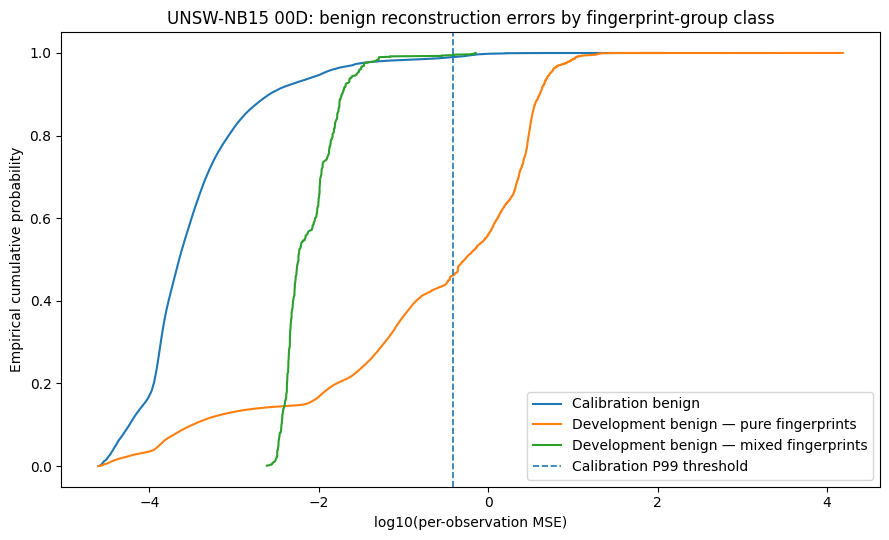

Saved diagnostic outputs to: /content/drive/MyDrive/EXPERIMENT1_V2/DATASETS/UNSW-NB15/modelling/preformal_mixed_label_fingerprint_diagnostic/v2_source_stratified_20260918


In [7]:

# ============================================================
# 00D-5. SAVE DIAGNOSTIC TABLES AND FIGURE
# ============================================================
atomic_write_csv(OUTPUT_ROOT / "benign_score_by_fingerprint_class.csv", SUMMARY)
atomic_write_csv(OUTPUT_ROOT / "mixed_fingerprint_false_positive_attribution.csv", FP_ATTRIBUTION)
atomic_write_csv(OUTPUT_ROOT / "development_benign_fingerprint_class_counts.csv", GROUP_COUNTS)
atomic_write_csv(OUTPUT_ROOT / "ct7_median_abs_z_by_fingerprint_class.csv", CT7_PER_FEATURE)

# Fingerprint-level diagnostic: each fingerprint is one deterministic model input.
# This table helps determine whether the mixed-group effect is concentrated in a
# few very large groups or is widespread across groups.
FP_LEVEL = (
    devx.groupby(["fingerprint_group_class", "feature_fingerprint"], sort=False)
        .agg(
            benign_rows=("row_id", "size"),
            median_total_mse=("total_mse", "median"),
            mean_total_mse=("total_mse", "mean"),
            above_calibration_p99_rate=("above_calibration_p99", "mean"),
        )
        .reset_index()
)
atomic_write_csv(OUTPUT_ROOT / "development_benign_fingerprint_level_summary.csv", FP_LEVEL)

# Publication/diagnostic figure: empirical CDF of log10 MSE.
import matplotlib.pyplot as plt

eps = np.finfo(np.float64).tiny
plt.figure(figsize=(9, 5.5))
for label, df in [
    ("Calibration benign", calx),
    ("Development benign — pure fingerprints", dev_pure),
    ("Development benign — mixed fingerprints", dev_mixed),
]:
    if len(df) == 0:
        continue
    vals = np.sort(np.log10(np.maximum(df["total_mse"].to_numpy(dtype=np.float64), eps)))
    y = np.arange(1, len(vals) + 1, dtype=np.float64) / len(vals)
    plt.plot(vals, y, label=label)

plt.axvline(np.log10(max(threshold, eps)), linestyle="--", linewidth=1.2,
            label="Calibration P99 threshold")
plt.xlabel("log10(per-observation MSE)")
plt.ylabel("Empirical cumulative probability")
plt.title("UNSW-NB15 00D: benign reconstruction errors by fingerprint-group class")
plt.legend()
plt.tight_layout()
fig_path = OUTPUT_ROOT / "figure_benign_mse_ecdf_by_fingerprint_class.png"
plt.savefig(fig_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved diagnostic outputs to:", OUTPUT_ROOT)



## Interpretation rule — descriptive, not an automatic gate

Interpret the MSE split **together with** the seven-feature CT-density statistic.

A mechanism-consistent pattern would be:

- **development benign from pure-benign fingerprints** has reconstruction-error and `ct7_pooled_median_abs_z` values close to calibration benign; and
- **development benign from mixed-label fingerprints** has substantially larger reconstruction error, elevated `ct7_pooled_median_abs_z`, and accounts for a disproportionate share of development-benign false positives.

That pattern would support the proposed end-to-end mechanism:

\[
\text{mixed-label model-view collisions}
\rightarrow
\text{exclusion from benign-only train/calibration}
\rightarrow
\text{under-representation of dense CT regimes}
\rightarrow
\text{calibration transfer failure}.
\]

If pure-benign development rows are also strongly shifted in both MSE and the seven `ct_*` counters, mixed-label groups are not sufficient to explain the failure. The next diagnostic should then examine fine-grained within-source capture/temporal composition.

Do **not** modify the partition, scaler, threshold, representation, or formal search based on one convenient statistic. Preserve the full diagnostic output first.


In [8]:

# ============================================================
# 00D-6. FREEZE DIAGNOSTIC MANIFEST — NO FORMAL AUTHORIZATION
# ============================================================
manifest = {
    "dataset": DATASET_NAME,
    "protocol_version": PROTOCOL_VERSION,
    "stage": OUTPUT_STAGE,
    "model_branch_version": MODEL_BRANCH_VERSION,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "parent_00c_manifest_hash": M00C.get("diagnostic_manifest_hash"),
    "partition_manifest_file_sha256": actual_partition_file_hash,
    "threshold_contract_hash": THRESHOLD_CONTRACT.get("contract_hash"),
    "threshold_percentile": 99.0,
    "threshold_value_recomputed_from_00c_calibration_benign": threshold,
    "calibration_benign_exceedance": float(np.mean(cal_exceed)),
    "development_benign_exceedance": float(devx["above_calibration_p99"].mean()),
    "development_benign_rows": int(len(devx)),
    "development_benign_pure_fingerprint_rows": int(len(dev_pure)),
    "development_benign_mixed_fingerprint_rows": int(len(dev_mixed)),
    "ct_density_features": CT7_ACTUAL,
    "calibration_ct7_pooled_median_abs_z": float(cal_ct.get("ct7_pooled_median_abs_z", np.nan)),
    "development_pure_ct7_pooled_median_abs_z": float(pure_ct.get("ct7_pooled_median_abs_z", np.nan)) if pure_ct else None,
    "development_mixed_ct7_pooled_median_abs_z": float(mixed_ct.get("ct7_pooled_median_abs_z", np.nan)) if mixed_ct else None,
    "attack_outcomes_accessed": False,
    "attack_scores_accessed": False,
    "attack_scores_computed": False,
    "final_test_features_accessed": False,
    "final_test_outcomes_accessed": False,
    "formal_model_selection_performed": False,
    "formal_notebook01_authorized": False,
    "automatic_protocol_change_authorized": False,
    "next_authorized_action": (
        "Interpret mixed-label fingerprint diagnostic. "
        "If pure-fingerprint development benign remains strongly shifted, "
        "run fine-grained within-source capture/temporal composition diagnostic. "
        "If mixed-label groups dominate the shift, freeze a protocol-level data-quality "
        "decision before changing any partition or threshold rule."
    ),
    "artifacts": {
        "benign_score_by_fingerprint_class_csv":
            str(OUTPUT_ROOT / "benign_score_by_fingerprint_class.csv"),
        "mixed_fingerprint_false_positive_attribution_csv":
            str(OUTPUT_ROOT / "mixed_fingerprint_false_positive_attribution.csv"),
        "development_benign_fingerprint_class_counts_csv":
            str(OUTPUT_ROOT / "development_benign_fingerprint_class_counts.csv"),
        "ct7_median_abs_z_by_fingerprint_class_csv":
            str(OUTPUT_ROOT / "ct7_median_abs_z_by_fingerprint_class.csv"),
        "development_benign_fingerprint_level_summary_csv":
            str(OUTPUT_ROOT / "development_benign_fingerprint_level_summary.csv"),
        "figure_benign_mse_ecdf_by_fingerprint_class":
            str(OUTPUT_ROOT / "figure_benign_mse_ecdf_by_fingerprint_class.png"),
    },
}
manifest["diagnostic_manifest_hash"] = sha256_bytes(
    canonical_json_bytes({
        k: v for k, v in manifest.items()
        if k not in {"created_at_utc", "diagnostic_manifest_hash"}
    })
)
atomic_write_json(OUTPUT_ROOT / "diagnostic_manifest.json", manifest)

print("\n00D DIAGNOSTIC COMPLETE")
print("Formal Notebook 01 authorization: BLOCKED")
print("No attack scores/outcomes accessed.")
print("No final-test access.")
print("\nReturn these files for interpretation:")
print("  1. benign_score_by_fingerprint_class.csv")
print("  2. mixed_fingerprint_false_positive_attribution.csv")
print("  3. development_benign_fingerprint_class_counts.csv")
print("  4. ct7_median_abs_z_by_fingerprint_class.csv")
print("  5. diagnostic_manifest.json")



00D DIAGNOSTIC COMPLETE
Formal Notebook 01 authorization: BLOCKED
No attack scores/outcomes accessed.
No final-test access.

Return these files for interpretation:
  1. benign_score_by_fingerprint_class.csv
  2. mixed_fingerprint_false_positive_attribution.csv
  3. development_benign_fingerprint_class_counts.csv
  4. ct7_median_abs_z_by_fingerprint_class.csv
  5. diagnostic_manifest.json
